# 01 · Exploratory Data Analysis: Road Traffic Accident (RTA) Dataset

**Project:** An Intelligent Traffic Violation Management System for Sri Lanka with ML-Based Dynamic Severity Assessment and Driver Risk Scoring
**Author:** Damma Monnankulama (20211211 / W1899305) · **Supervisor:** Ms. Asini Silva

**Purpose of this notebook.** Before cleaning or modelling, we look at the raw data to understand it (Proposal §3.4.2, *Data quality assessment*). We want to know:

1. What the dataset contains: size, column types and cardinality.
2. Data quality problems: missing values, placeholder tokens, inconsistent or corrupted labels.
3. The shape of the target `Accident_severity`, and how imbalanced it is.
4. Which contextual factors (time, lighting, weather, road, driver) relate to severity.
5. Which columns would **leak** post-accident information into Model 1 (the Accident Severity Predictor), and so must be excluded.

**Dataset.** Road accident records from the Addis Ababa Sub-City police departments, published on Kaggle under **CC BY 4.0**. The Sri Lanka Police records were not accessible; this dataset was agreed as a structurally similar alternative (Proposal §3.4.1).

> The findings from this notebook drive every decision in `02_data_preprocessing.ipynb`.

## 0. Setup

In [1]:
# --- Environment & paths -------------------------------------------------
# Works both locally (conda env `accident-severity-poc`) and on Google Colab.
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    # On Colab: upload the project folder to Google Drive, then set its path here.
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = Path("/content/drive/MyDrive/fyp-poc-v4")
else:
    # Locally: notebooks live in <project>/notebooks
    PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

RAW_PATH       = PROJECT_ROOT / "data" / "raw" / "RTA Dataset.csv"
PROCESSED_DIR  = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR    = PROJECT_ROOT / "reports" / "figures"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

assert RAW_PATH.exists(), f"Dataset not found at {RAW_PATH}"
print("Project root:", PROJECT_ROOT)
print("Running on Colab:", IN_COLAB)

Project root: /Users/dammamonnankulama/FYP/fyp-poc-v4
Running on Colab: False


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
RANDOM_SEED = 42

# Plot style: recessive grid/axes, thin marks, one consistent palette.
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE = "#2a78d6"
# Severity is ordinal -> one hue, light (slight) to dark (fatal)
SEVERITY_ORDER  = ["Slight Injury", "Serious Injury", "Fatal injury"]
SEVERITY_COLORS = {"Slight Injury": "#86b6ef", "Serious Injury": "#2a78d6", "Fatal injury": "#104281"}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "legend.frameon": False, "legend.fontsize": 9, "figure.dpi": 110,
})

def save_fig(fig, name):
    fig.savefig(FIGURES_DIR / f"{name}.png", bbox_inches="tight", dpi=150)

## 1. Load the raw data

In [3]:
df = pd.read_csv(RAW_PATH)
print(f"Rows: {df.shape[0]:,}   Columns: {df.shape[1]}")
df.head()

Rows: 12,316   Columns: 32


,Time,Day_of_week,Age_band_of_driver,Sex_of_driver,Educational_level,Vehicle_driver_relation,Driving_experience,Type_of_vehicle,Owner_of_vehicle,Service_year_of_vehicle,Defect_of_vehicle,Area_accident_occured,Lanes_or_Medians,Road_allignment,Types_of_Junction,Road_surface_type,Road_surface_conditions,Light_conditions,Weather_conditions,Type_of_collision,Number_of_vehicles_involved,Number_of_casualties,Vehicle_movement,Casualty_class,Sex_of_casualty,Age_band_of_casualty,Casualty_severity,Work_of_casuality,Fitness_of_casuality,Pedestrian_movement,Cause_of_accident,Accident_severity
0,17:02:00,Monday,18-30,Male,Above high school,Employee,1-2yr,Automobile,Owner,Above 10yr,No defect,Residential areas,NaN,Tangent road with flat terrain,No junction,Asphalt roads,Dry,Daylight,Normal,Collision with roadside-parked vehicles,2,2,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Moving Backward,Slight Injury
1,17:02:00,Monday,31-50,Male,Junior high school,Employee,Above 10yr,Public (> 45 seats),Owner,5-10yrs,No defect,Office areas,Undivided Two way,Tangent road with flat terrain,No junction,Asphalt roads,Dry,Daylight,Normal,Vehicle with vehicle collision,2,2,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury
2,17:02:00,Monday,18-30,Male,Junior high school,Employee,1-2yr,Lorry (41?100Q),Owner,NaN,No defect,Recreational areas,other,NaN,No junction,Asphalt roads,Dry,Daylight,Normal,Collision with roadside objects,2,2,Going straight,Driver or rider,Male,31-50,3,Driver,NaN,Not a Pedestrian,Changing lane to the left,Serious Injury
3,1:06:00,Sunday,18-30,Male,Junior high school,Employee,5-10yr,Public (> 45 seats),Governmental,NaN,No defect,Office areas,other,Tangent road with mild grade and flat terrain,Y Shape,Earth roads,Dry,Darkness - lights lit,Normal,Vehicle with vehicle collision,2,2,Going straight,Pedestrian,Female,18-30,3,Driver,Normal,Not a Pedestrian,Changing lane to the right,Slight Injury
4,1:06:00,Sunday,18-30,Male,Junior high school,Employee,2-5yr,NaN,Owner,5-10yrs,No defect,Industrial areas,other,Tangent road with flat terrain,Y Shape,Asphalt roads,Dry,Darkness - lights lit,Normal,Vehicle with vehicle collision,2,2,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury


In [4]:
# Column overview: type, number of distinct values, missing count/% and an example value
overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "n_missing": df.isna().sum(),
    "pct_missing": (df.isna().mean() * 100).round(2),
    "example": df.iloc[0],
})
overview

,dtype,n_unique,n_missing,pct_missing,example
Time,str,1074,0,0.00,17:02:00
Day_of_week,str,7,0,0.00,Monday
Age_band_of_driver,str,5,0,0.00,18-30
Sex_of_driver,str,3,0,0.00,Male
Educational_level,str,7,741,6.02,Above high school
Vehicle_driver_relation,str,4,579,4.70,Employee
Driving_experience,str,7,829,6.73,1-2yr
Type_of_vehicle,str,17,950,7.71,Automobile
Owner_of_vehicle,str,4,482,3.91,Owner
Service_year_of_vehicle,str,6,3928,31.89,Above 10yr


**Observations**
- Every column except `Number_of_vehicles_involved` and `Number_of_casualties` is **categorical** (stored as text). `Time` is an `HH:MM:SS` string that we will turn into features.
- The column groups are: **time** (Time, Day_of_week), **driver** (age band, sex, education, experience), **vehicle** (type, owner, service year, defect), **road/environment** (area, lanes, alignment, junction, surface, light, weather), **crash outcome** (collision type, vehicles involved, casualties, casualty details) and the **target** `Accident_severity`.

## 2. Data quality assessment

### 2.1 Duplicates

In [5]:
print("Exact duplicate rows:", df.duplicated().sum())

Exact duplicate rows: 0


### 2.2 Missing values: true NaN *and* hidden placeholders
A NaN count alone understates how much data is missing. Several columns use text placeholders such as `"na"`, `"Unknown"` or `"unknown"` that carry no information. Below we count both.

In [6]:
PLACEHOLDERS = {"na", "unknown", "Unknown"}

missing = pd.DataFrame({
    "NaN": df.isna().sum(),
    "placeholder": df.apply(lambda s: s.astype(str).str.strip().isin(PLACEHOLDERS).sum()),
})
missing["total_missing"] = missing["NaN"] + missing["placeholder"]
missing["pct_total"] = (missing["total_missing"] / len(df) * 100).round(1)
missing = missing[missing["total_missing"] > 0].sort_values("pct_total", ascending=False)
missing

,NaN,placeholder,total_missing,pct_total
Service_year_of_vehicle,3928,2883,6811,55.3
Casualty_class,0,4443,4443,36.1
Casualty_severity,0,4443,4443,36.1
Age_band_of_casualty,0,4443,4443,36.1
Sex_of_casualty,0,4443,4443,36.1
Defect_of_vehicle,4427,0,4427,35.9
Work_of_casuality,3198,19,3217,26.1
Fitness_of_casuality,2635,0,2635,21.4
Age_band_of_driver,0,1548,1548,12.6
Types_of_Junction,887,191,1078,8.8


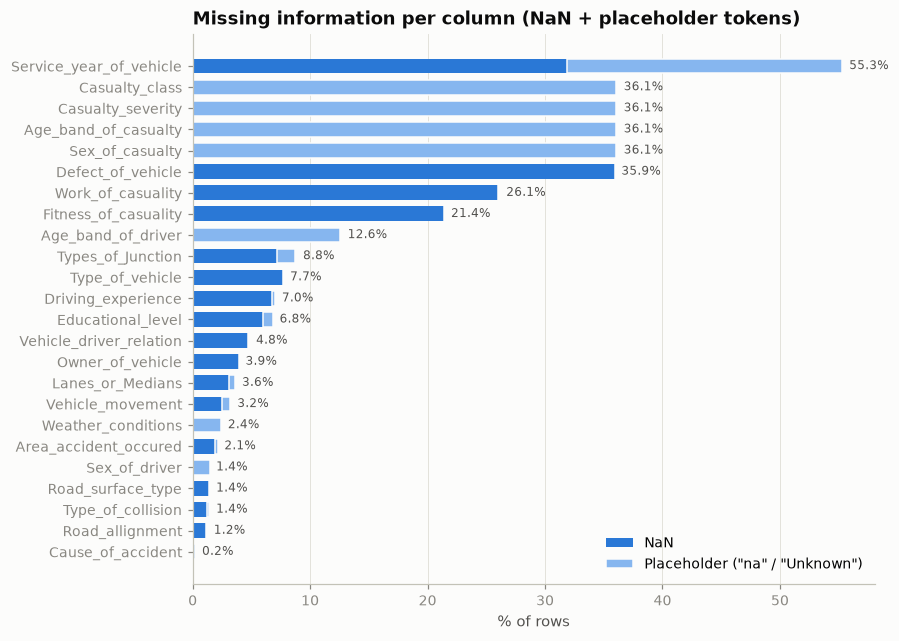

In [7]:
fig, ax = plt.subplots(figsize=(8, 6.5))
m = missing.sort_values("pct_total")
ax.barh(m.index, m["NaN"] / len(df) * 100, color=BLUE, height=0.7, label="NaN")
ax.barh(m.index, m["placeholder"] / len(df) * 100, left=m["NaN"] / len(df) * 100,
        color="#86b6ef", height=0.7, label='Placeholder ("na" / "Unknown")', edgecolor=SURFACE, linewidth=1)
for i, v in enumerate(m["pct_total"]):
    ax.text(v + 0.6, i, f"{v:.1f}%", va="center", fontsize=8, color=INK_2)
ax.set_xlabel("% of rows")
ax.set_title("Missing information per column (NaN + placeholder tokens)", loc="left")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
save_fig(fig, "01_missing_values")
plt.show()

**Observations**
- `Service_year_of_vehicle` (about 55% missing in total) and `Defect_of_vehicle` (about 36%) are mostly empty. They are unreliable as features.
- The four casualty columns share **exactly the same 4,443 `"na"` rows**: no casualty details were recorded for those accidents.
- The target `Accident_severity` has **no missing values**, so no rows have to be dropped for lack of a label.

### 2.3 Inconsistent and corrupted labels
Some category labels differ only by whitespace or case, or show text corruption from the original data entry.

In [8]:
cat_cols = df.select_dtypes(exclude="number").columns

# (a) labels with leading/trailing or double whitespace
ws = {c: sorted({v for v in df[c].dropna().unique() if v != v.strip() or "  " in v})
      for c in cat_cols}
print("Labels with stray whitespace:")
for c, vals in ws.items():
    if vals:
        print(f"  {c}: {vals}")

# (b) known corruption patterns
patterns = {"'?' used instead of '-'": r"\?", "'statioNot a Pedestrianry' (find/replace damage)": "statioNot",
            "'NormalNormal' (duplicated token)": "NormalNormal", "concatenated labels": r"areasOffice"}
print("\nCorruption patterns:")
for desc, pat in patterns.items():
    for c in cat_cols:
        hits = df[c].dropna()[df[c].dropna().str.contains(pat, regex=True)].unique()
        if len(hits):
            print(f"  {desc} -> {c}: {list(hits)[:3]}{' ...' if len(hits) > 3 else ''}")

# (c) case-only duplicates, e.g. 'unknown' vs 'Unknown', 'other' vs 'Other'
print("\nCase-inconsistent labels:")
for c in cat_cols:
    vals = df[c].dropna().unique()
    lower = pd.Series(vals).str.strip().str.lower()
    dup = lower[lower.duplicated(keep=False)]
    if len(dup):
        print(f"  {c}: {sorted(set(pd.Series(vals)[dup.index]))}")
    elif any(v in ("unknown", "other") for v in vals):
        print(f"  {c}: lowercase {[v for v in vals if v in ('unknown', 'other')]} (vs. 'Unknown'/'Other' in other columns)")

Labels with stray whitespace:
  Area_accident_occured: ['  Market areas', '  Recreational areas', ' Church areas', ' Hospital areas', ' Industrial areas', ' Outside rural areas']
  Pedestrian_movement: ['Crossing from offside - masked by  parked or statioNot a Pedestrianry vehicle', 'In carriageway, statioNot a Pedestrianry - not crossing  (standing or playing)', 'In carriageway, statioNot a Pedestrianry - not crossing  (standing or playing) - masked by parked or statioNot a Pedestrianry vehicle']

Corruption patterns:
  '?' used instead of '-' -> Type_of_vehicle: ['Lorry (41?100Q)', 'Public (13?45 seats)', 'Lorry (11?40Q)']
  'statioNot a Pedestrianry' (find/replace damage) -> Pedestrian_movement: ['Crossing from nearside - masked by parked or statioNot a Pedestrianry vehicle', 'Crossing from offside - masked by  parked or statioNot a Pedestrianry vehicle', 'In carriageway, statioNot a Pedestrianry - not crossing  (standing or playing)'] ...
  'NormalNormal' (duplicated token) -> Fitn

**Observations.** These must be fixed before encoding. Otherwise `" Recreational areas"` and `"Recreational areas"` become two separate one-hot features.
- `Area_accident_occured`: leading spaces on 6 labels, and `"Rural village areasOffice areas"` (two labels merged together).
- `Pedestrian_movement`: the word *stationary* was damaged by an earlier find/replace (`"statioNot a Pedestrianry"`).
- `Type_of_vehicle`: `?` stands in for a dash (`"Lorry (41?100Q)"` should read `"Lorry (41-100Q)"`).
- `Fitness_of_casuality`: `"NormalNormal"`; `Driving_experience`: `"unknown"`; `Lanes_or_Medians`: `"other"`.
- `Road_allignment`: `"Tangent road with mountainous terrain and"` is truncated.

## 3. Target variable: `Accident_severity`

In [9]:
target_counts = df["Accident_severity"].value_counts().reindex(SEVERITY_ORDER)
target_pct = (target_counts / len(df) * 100).round(2)
target_summary = pd.DataFrame({"count": target_counts, "percent": target_pct})
print(target_summary, "\n")
print(f"Majority-class baseline accuracy: {target_pct.max():.2f}%  (always predicting '{target_pct.idxmax()}')")
print(f"Imbalance ratio Slight : Fatal = {target_counts.iloc[0] / target_counts.iloc[2]:.0f} : 1")

                   count  percent
Accident_severity                
Slight Injury      10415    84.56
Serious Injury      1743    14.15
Fatal injury         158     1.28 

Majority-class baseline accuracy: 84.56%  (always predicting 'Slight Injury')
Imbalance ratio Slight : Fatal = 66 : 1


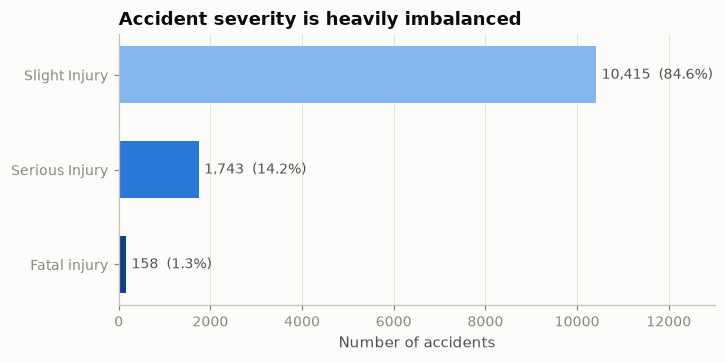

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.barh(SEVERITY_ORDER[::-1], target_counts[SEVERITY_ORDER[::-1]],
               color=[SEVERITY_COLORS[s] for s in SEVERITY_ORDER[::-1]], height=0.6)
for b, s in zip(bars, SEVERITY_ORDER[::-1]):
    ax.text(b.get_width() + 120, b.get_y() + b.get_height() / 2,
            f"{target_counts[s]:,}  ({target_pct[s]:.1f}%)", va="center", fontsize=9, color=INK_2)
ax.set_xlim(0, target_counts.max() * 1.25)
ax.set_xlabel("Number of accidents")
ax.set_title("Accident severity is heavily imbalanced", loc="left")
ax.grid(axis="y", visible=False)
save_fig(fig, "02_target_distribution")
plt.show()

**Observations: the central challenge (Research Challenge 1)**
- **Slight Injury makes up 84.6%** of records, **Serious 14.2%** and **Fatal only 1.3% (158 cases)**.
- A model that always predicts *Slight* scores **84.56% accuracy**, exactly the majority baseline in the POC (Proposal Table 3.13). Accuracy is therefore misleading here. We will evaluate with **balanced accuracy, macro-F1 and per-class recall/precision** (Proposal §3.9.2).
- With only 158 fatal cases, the train/test split **must be stratified**, and imbalance correction (class weights, SMOTE-family resampling) is needed. Resampling must be applied **only to the training split** to avoid leakage. That happens in the modelling notebook, not in preprocessing.

## 4. Temporal patterns

In [11]:
times = pd.to_datetime(df["Time"], format="%H:%M:%S", errors="coerce")
print("Unparseable Time values:", times.isna().sum())
hour = times.dt.hour

def severity_rates(key):
    """Per category: count, % Serious, % Fatal, % Serious+Fatal (severe)."""
    ct = pd.crosstab(key, df["Accident_severity"])
    out = pd.DataFrame({"n": ct.sum(axis=1)})
    out["serious_pct"] = ct["Serious Injury"] / out["n"] * 100
    out["fatal_pct"] = ct["Fatal injury"] / out["n"] * 100
    out["severe_pct"] = out["serious_pct"] + out["fatal_pct"]
    return out.round(2)

hourly = severity_rates(hour.rename("hour"))
overall_fatal = (df["Accident_severity"] == "Fatal injury").mean() * 100
overall_severe = df["Accident_severity"].isin(["Serious Injury", "Fatal injury"]).mean() * 100
print(f"Overall fatal rate: {overall_fatal:.2f}%   Overall severe (serious+fatal) rate: {overall_severe:.2f}%")

Unparseable Time values: 0


Overall fatal rate: 1.28%   Overall severe (serious+fatal) rate: 15.44%


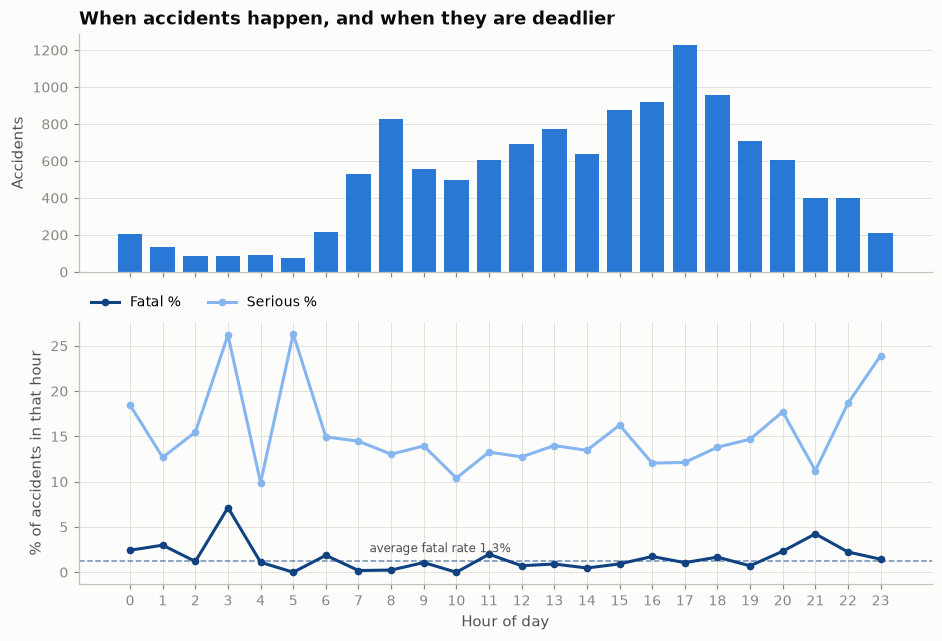

,n,serious_pct,fatal_pct,severe_pct
hour,,,,
3,84,26.19,7.14,33.33
21,401,11.22,4.24,15.46
1,134,12.69,2.99,15.67
0,206,18.45,2.43,20.87
20,604,17.72,2.32,20.03
22,402,18.66,2.24,20.90


In [12]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True, gridspec_kw={"height_ratios": [1, 1.1]})
ax1.bar(hourly.index, hourly["n"], color=BLUE, width=0.75)
ax1.set_ylabel("Accidents")
ax1.set_title("When accidents happen, and when they are deadlier", loc="left")
ax1.grid(axis="x", visible=False)

ax2.plot(hourly.index, hourly["fatal_pct"], color="#104281", lw=2, marker="o", ms=4, label="Fatal %")
ax2.plot(hourly.index, hourly["serious_pct"], color="#86b6ef", lw=2, marker="o", ms=4, label="Serious %")
ax2.axhline(overall_fatal, color="#104281", lw=1, ls="--", alpha=0.6)
ax2.text(9.5, overall_fatal + 0.6, f"average fatal rate {overall_fatal:.1f}%", va="bottom", ha="center", fontsize=8, color=INK_2)
ax2.set_ylabel("% of accidents in that hour")
ax2.set_xlabel("Hour of day")
ax2.set_xticks(range(0, 24))
ax2.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2)
save_fig(fig, "03_hourly_pattern")
plt.show()

hourly.sort_values("fatal_pct", ascending=False).head(6)

In [13]:
dow_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
severity_rates(df["Day_of_week"]).reindex(dow_order)

,n,serious_pct,fatal_pct,severe_pct
Day_of_week,,,,
Monday,1681,12.14,0.71,12.85
Tuesday,1770,14.52,0.96,15.48
Wednesday,1840,14.24,1.03,15.27
Thursday,1851,14.69,1.19,15.88
Friday,2041,15.34,0.78,16.12
Saturday,1666,14.71,2.22,16.93
Sunday,1467,12.95,2.39,15.34


**Observations**
- Accident **volume** peaks in the afternoon and evening rush (about 15:00–18:00).
- The **fatal rate** is far higher at **night and early morning**: hour 03 reaches 7.1%, and hours 20–22 and 00–01 run at 2.2–4.2%, against the 1.3% average. The serious-injury rate also rises after 22:00. The night-time hours contain few records, so individual hourly rates are noisy. Grouping them into periods (notebook 02) gives more stable estimates.
- This supports the core premise of the proposal: **the same violation is more dangerous at night**. Hour of day (and a derived *time-of-day period*) should be a feature.
- **Weekends are deadlier.** Saturday (2.2%) and Sunday (2.4%) have roughly double the fatal rate of weekdays (0.7–1.2%), even though Friday has the most accidents. This justifies an `is_weekend` feature.

## 5. Contextual factors vs severity

For each candidate context feature we plot the **severe rate (Serious + Fatal %)** per category, with the dataset average as a reference line. Categories with fewer than 30 records are hidden because their rates are unreliable.

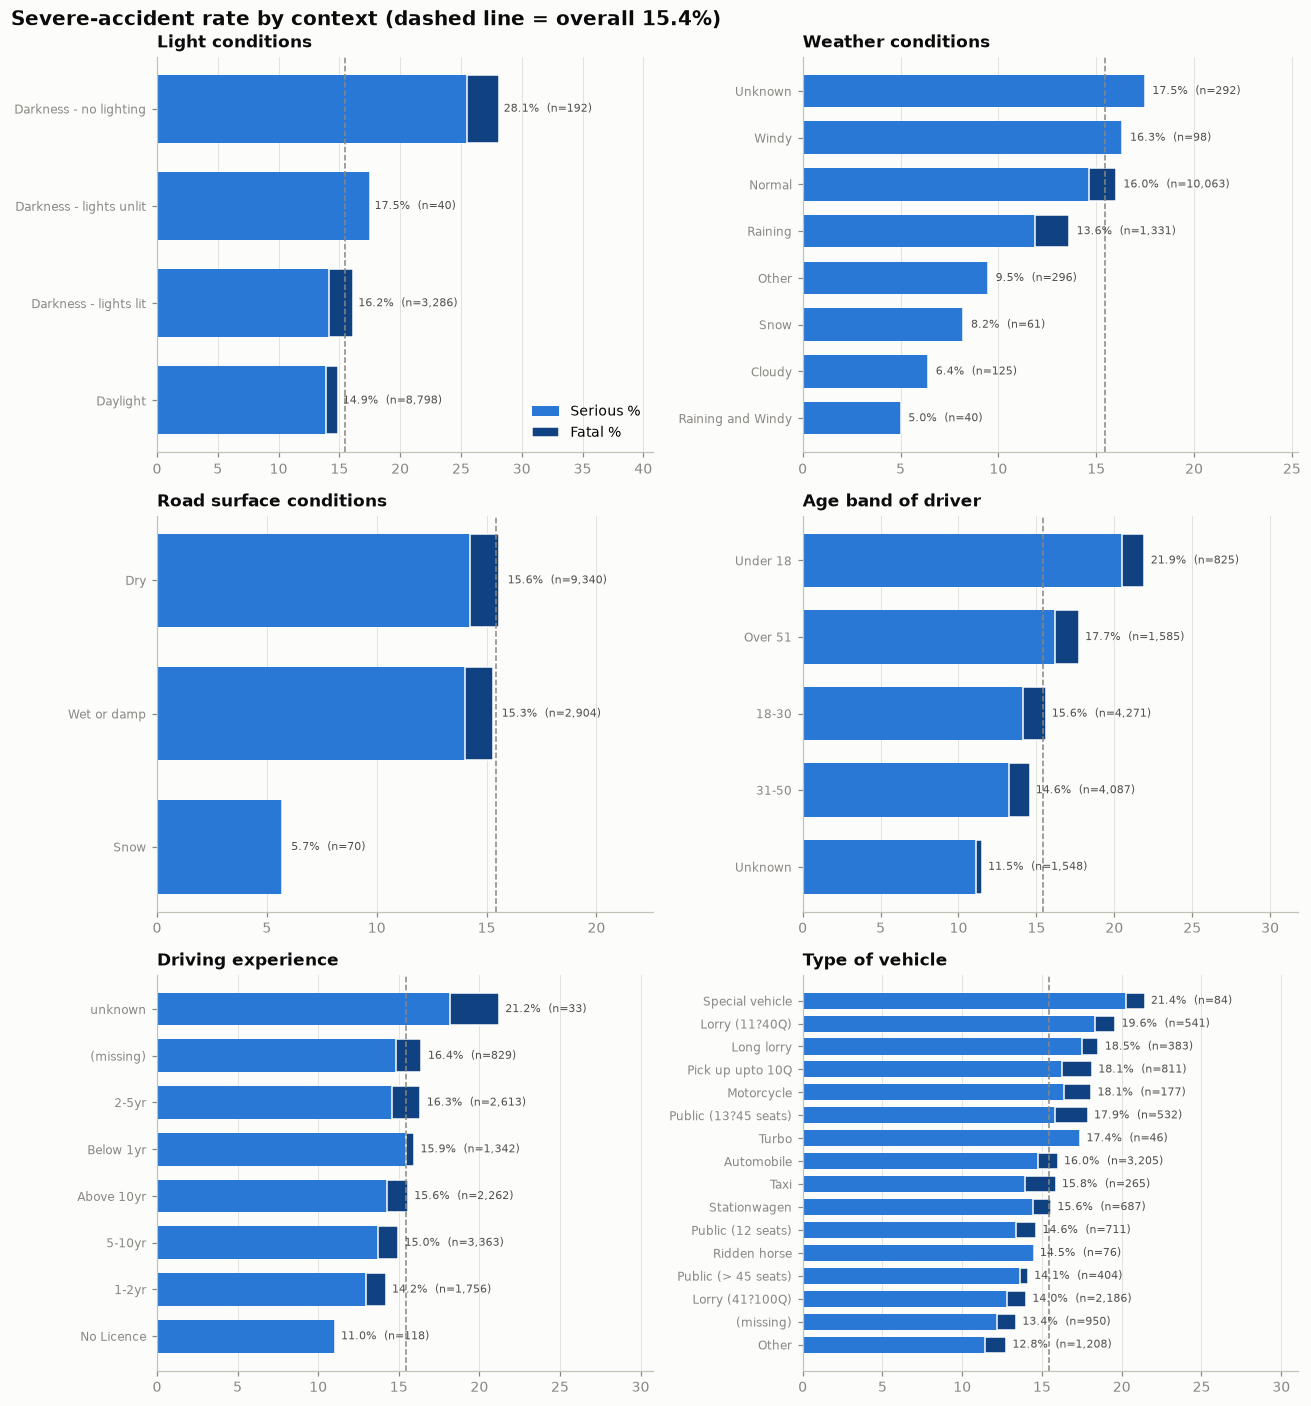

In [14]:
context_features = ["Light_conditions", "Weather_conditions", "Road_surface_conditions",
                    "Age_band_of_driver", "Driving_experience", "Type_of_vehicle"]

fig, axes = plt.subplots(3, 2, figsize=(12, 13))
for ax, col in zip(axes.ravel(), context_features):
    r = severity_rates(df[col].fillna("(missing)"))
    r = r[r["n"] >= 30].sort_values("severe_pct")
    ax.barh(r.index, r["serious_pct"], color=SEVERITY_COLORS["Serious Injury"], height=0.7, label="Serious %")
    ax.barh(r.index, r["fatal_pct"], left=r["serious_pct"], color=SEVERITY_COLORS["Fatal injury"],
            height=0.7, label="Fatal %", edgecolor=SURFACE, linewidth=1)
    ax.axvline(overall_severe, color=MUTED, lw=1, ls="--")
    for i, (v, n) in enumerate(zip(r["severe_pct"], r["n"])):
        ax.text(v + 0.4, i, f"{v:.1f}%  (n={n:,})", va="center", fontsize=7.5, color=INK_2)
    ax.set_xlim(0, r["severe_pct"].max() * 1.45)
    ax.set_title(col.replace("_", " "), loc="left", fontsize=11)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=8)
axes[0, 0].legend(loc="lower right")
fig.suptitle(f"Severe-accident rate by context (dashed line = overall {overall_severe:.1f}%)",
             x=0.01, ha="left", fontsize=13, fontweight="bold", color=INK)
fig.tight_layout()
save_fig(fig, "04_context_vs_severity")
plt.show()

In [15]:
# Cause of accident is the closest proxy in this dataset to the *violation type* (Model 1 input)
cause = severity_rates(df["Cause_of_accident"])
cause[cause["n"] >= 30].sort_values("severe_pct", ascending=False)

,n,serious_pct,fatal_pct,severe_pct
Cause_of_accident,,,,
Overspeed,61,24.59,1.64,26.23
Overloading,59,16.95,3.39,20.34
Driving to the left,284,18.66,1.41,20.07
Driving at high speed,174,17.82,1.15,18.97
Overtaking,430,17.44,0.93,18.37
Overturning,149,15.44,1.34,16.78
Moving Backward,1137,14.25,2.29,16.53
Driving carelessly,1402,14.91,1.57,16.48
Getting off the vehicle improperly,197,14.72,1.52,16.24


**Observations**
- **Light conditions:** *Darkness – no lighting* has a severe rate of 28.1%, about 1.8× the 15.4% average (though only 192 records). *Darkness – lights lit* has double the fatal rate of daylight (2.0% vs 1.0%).
- **Driver age:** *Under 18* drivers have the highest severe rate (21.9%), followed by *Over 51* (17.7%).
- **Weather** and **road surface** show surprisingly little effect. *Wet* roads are no more severe than *Dry*, and *Raining* is slightly below average. Most records are *Normal*/*Dry*, and adverse-weather crashes may happen at lower speeds. This dataset doesn't support a simple "rain = more dangerous" rule; we let the model learn the weight instead.
- **Vehicle type:** heavy vehicles (*Special vehicle*, mid-size and long *lorries*) and *motorcycles* sit above the average.
- **Cause_of_accident** is the dataset's closest equivalent to the **violation type** an officer would record (a Model 1 input, Proposal §3.4.4). Speed-related violations have the highest severe rates: *Overspeed* (26.2%), *Driving at high speed* (19.0%), *Overtaking* (18.4%), plus *Overloading* (20.3%). This is the kind of difference a context-aware penalty should reflect.

## 6. Strength of association with the target (Cramér's V)

**Cramér's V** measures the association between two categorical variables, from 0 (none) to 1 (perfect). We use the bias-corrected version (Bergsma, 2013). It ranks every column by how informative it is about severity, and an unusually high value can also flag **leakage**.

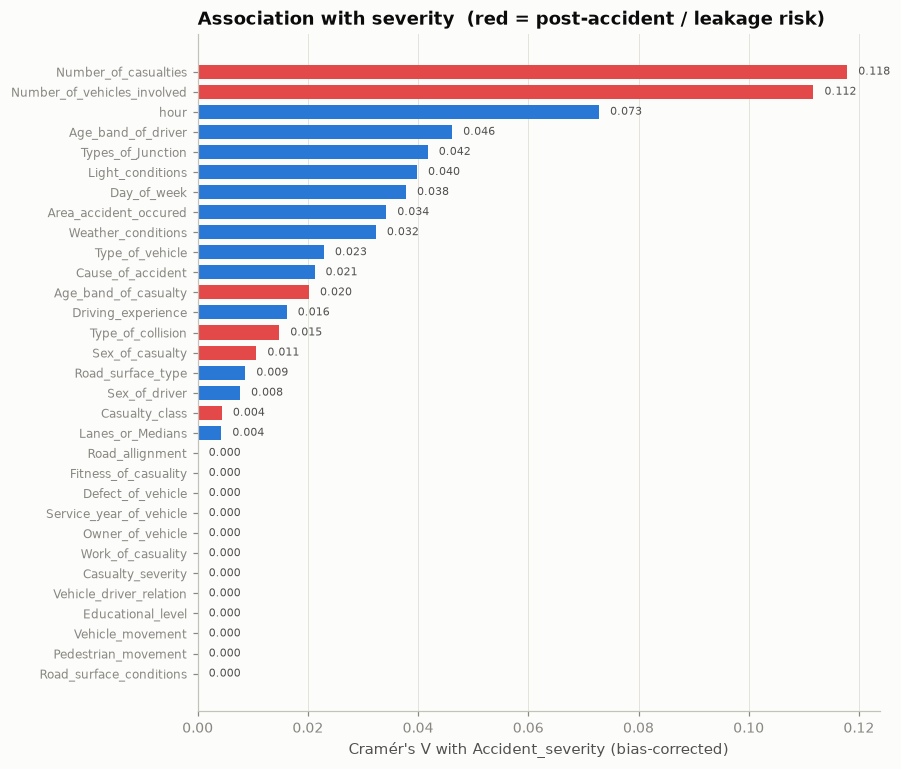

,cramers_v
Number_of_casualties,0.1179
Number_of_vehicles_involved,0.1117
hour,0.0728
Age_band_of_driver,0.0462
Types_of_Junction,0.0418
Light_conditions,0.0398
Day_of_week,0.0378
Area_accident_occured,0.0342
Weather_conditions,0.0323
Type_of_vehicle,0.0229


In [16]:
def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2 = chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum()
    phi2 = chi2 / n
    r, k = ct.shape
    phi2corr = max(0, phi2 - (k - 1) * (r - 1) / (n - 1))
    rcorr, kcorr = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2corr / max(1e-12, min(kcorr - 1, rcorr - 1)))

assoc_df = df.drop(columns=["Time"]).assign(hour=hour)
assoc = pd.Series({c: cramers_v(assoc_df[c].fillna("(missing)"), df["Accident_severity"])
                   for c in assoc_df.columns if c != "Accident_severity"}).sort_values()

# Columns that describe the OUTCOME of the crash (unknown at violation time)
POST_ACCIDENT = ["Number_of_casualties", "Number_of_vehicles_involved", "Type_of_collision",
                 "Casualty_class", "Sex_of_casualty", "Age_band_of_casualty", "Casualty_severity",
                 "Work_of_casuality", "Fitness_of_casuality", "Pedestrian_movement"]

fig, ax = plt.subplots(figsize=(8, 8))
colors = ["#e34948" if c in POST_ACCIDENT else BLUE for c in assoc.index]
ax.barh(assoc.index, assoc.values, color=colors, height=0.7)
for i, v in enumerate(assoc.values):
    ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=7.5, color=INK_2)
ax.set_xlabel("Cramér's V with Accident_severity (bias-corrected)")
ax.set_title("Association with severity  (red = post-accident / leakage risk)", loc="left")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=8)
save_fig(fig, "05_cramers_v")
plt.show()
assoc.sort_values(ascending=False).round(4).to_frame("cramers_v")

**Observations**
- No single column is strongly associated with severity (every V is below 0.12). Severity depends on **combinations** of factors, which suggests non-linear models (tree ensembles, neural networks) and explains why the POC baselines struggled.
- The **two strongest signals are post-accident columns**: `Number_of_casualties` (0.118) and `Number_of_vehicles_involved` (0.112). They score high because they describe the crash's outcome. Using them would inflate results while being unavailable at violation time.
- Among the context features, **hour of day (0.073)** is the strongest by a clear margin, followed by **driver age band, junction type, light conditions and day of week** (about 0.04 each).
- Some context features (`Road_allignment`, `Road_surface_conditions`, `Lanes_or_Medians`) show almost no association *on their own*. We still keep them for now, since they may matter in combination with others. Their real contribution will be tested with model-based feature importance and SHAP in the modelling notebooks.

## 7. Leakage review and feature-selection decision

**Model 1 predicts severity at the moment an officer records a *violation*. No crash has happened yet.** Any column that is only known *after* a crash would let the model "see the answer" during training, then fail in deployment. Proposal §3.4.2 and Appendix E already state that only **context** fields are retained.

| Group | Columns | Decision | Reason |
|---|---|---|---|
| Time | `Time` → hour, period, `Day_of_week` | **Keep** | Appendix E: time of day, day of week |
| Environment | `Light_conditions`, `Weather_conditions`, `Road_surface_conditions` | **Keep** | Appendix E: light condition, weather |
| Road | `Road_surface_type`, `Road_allignment`, `Lanes_or_Medians`, `Types_of_Junction`, `Area_accident_occured` | **Keep** | Appendix E: road type |
| Driver | `Age_band_of_driver`, `Driving_experience` | **Keep** | Appendix E: driver age, licence age (experience is the closest proxy) |
| Vehicle | `Type_of_vehicle` | **Keep** | Appendix E: vehicle class |
| Violation | `Cause_of_accident` | **Keep** | Closest proxy to *violation type* (Model 1 input, §3.4.4) |
| Post-accident outcome | `Number_of_casualties`, `Number_of_vehicles_involved`, `Type_of_collision`, all `Casualty_*`, `Work_of_casuality`, `Fitness_of_casuality`, `Pedestrian_movement` | **Drop** | Unknown at violation time → target leakage. Appendix E excludes collision type |
| Sensitive / not justified | `Sex_of_driver`, `Educational_level` | **Drop** | Not in Appendix E. Penalising by sex or education raises fairness concerns (Ch. 4, ethical issues) |
| Low quality | `Service_year_of_vehicle` (~55% missing), `Defect_of_vehicle` (~36% missing, undocumented codes `5`/`7`) | **Drop** | Too sparse or uninterpretable |
| Not relevant | `Vehicle_driver_relation`, `Owner_of_vehicle`, `Vehicle_movement` | **Drop** | Not in Appendix E. Ownership doesn't describe risk context; movement is crash-event detail |

**Not available in this dataset:** *holiday status* and *speed limit* (Appendix E). They are documented as a dataset limitation; holiday status could be added later if accident dates become available.

## 8. Summary of findings → actions for preprocessing

| # | Finding | Action in `02_data_preprocessing` |
|---|---|---|
| 1 | 12,316 rows, 32 columns, no duplicates, no missing target | Keep all rows (dropping rows would lose scarce fatal cases) |
| 2 | Stray whitespace, `?` corruption, merged/truncated labels, case inconsistencies | Normalise text and apply an explicit, documented correction map |
| 3 | Missing values appear as NaN, `na`, `unknown`, `Unknown` | Unify into one `Unknown` category (informative, not imputed) |
| 4 | Fatal rate is higher at night, in darkness and at weekends | Engineer `hour`, `time_of_day` and `is_night` from `Time`; `is_weekend` from `Day_of_week` |
| 5 | Severe class imbalance (84.6 / 14.2 / 1.3 %) | Encode target ordinally (0/1/2). Stratified split and resampling come later, **train-only** |
| 6 | Post-accident columns leak the outcome | Exclude from the Model 1 feature set |
| 7 | Sex/education are sensitive; service-year/defect are sparse | Exclude from the Model 1 feature set |

➡️ **Next:** `02_data_preprocessing.ipynb`